# MiBici Guadalajara - EDA para agrupar estaciones por patrón de uso

**Pregunta:** ¿Qué estaciones de MiBici comparten patrones de uso y dónde se ubican?

**Objetivo de este notebook (1.0):** análisis exploratorio inicial (EDA) de los datos abiertos de MiBici
(enero 2025 - septiembre 2026) para entender la calidad de los datos y decidir qué *features* por estación
se usarán después en el modelo de clustering.

**Fuente:** <https://mibici.net/es/datos-abiertos/>

| Archivo | Ubicación | Contenido |
|---|---|---|
| `datos_abiertos_AAAA_MM.csv` | `data/raw/Viajes/` | Un viaje por fila (origen, destino, inicio, fin, usuario) |
| `nomenclatura_AAAA_MM.csv` | `data/raw/Nomenclatura/` | Catálogo de estaciones (id, nombre, lat, lon, capacidad) |

> Los datos se descargan con `python src/data/download_raw_data.py --years 2025 2026` (ejecutado desde `MLOps_Equipo30/`).
> `data/raw/` está en `.gitignore`: los datos crudos **no** se versionan y son inmutables.

## 1. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

# El notebook vive en MLOps_Equipo30/notebooks/, la raíz del proyecto es su carpeta padre
cwd = Path.cwd().resolve()
PROJ_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
RAW_DIR = PROJ_ROOT / "data" / "raw"
TRIPS_DIR = RAW_DIR / "Viajes"
STATIONS_DIR = RAW_DIR / "Nomenclatura"
FIGURES_DIR = PROJ_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

trip_files = sorted(TRIPS_DIR.glob("datos_abiertos_202[56]_*.csv"))
print(f"Raíz del proyecto: {PROJ_ROOT}")
print(f"Archivos de viajes encontrados: {len(trip_files)} ({trip_files[0].stem[-7:]} -> {trip_files[-1].stem[-7:]})")

Raíz del proyecto: C:\Users\diego\OneDrive\Documentos\Python\TC5061-Proyecto-Equipo30\MLOps_Equipo30
Archivos de viajes encontrados: 21 (2025_01 -> 2026_09)


## 2. Carga de datos

Detalles que conviene conocer:

- Los CSV vienen en **latin-1**; además el encabezado `Año_de_nacimiento` aparece con distinta codificación
  según el mes, por eso se renombran las columnas **por posición**.
- Se leen solo las columnas necesarias y con tipos compactos para no saturar la memoria (~8 millones de filas).

In [2]:
TRIP_COLS = ["viaje_id", "usuario_id", "genero", "anio_nacimiento", "inicio", "fin", "origen_id", "destino_id"]

def read_trips(path: Path) -> pd.DataFrame:
    df = pd.read_csv(
        path,
        encoding="latin-1",
        header=0,
        names=TRIP_COLS,
        dtype={"viaje_id": "int64", "usuario_id": "int64", "genero": "string",
               "origen_id": "int32", "destino_id": "int32"},
    )
    df["archivo"] = path.stem[-7:]  # AAAA_MM del archivo de origen
    return df

trips = pd.concat([read_trips(p) for p in trip_files], ignore_index=True)
print(f"Viajes cargados: {len(trips):,}")
trips.head()

Viajes cargados: 7,894,097


,viaje_id,usuario_id,genero,anio_nacimiento,inicio,fin,origen_id,destino_id,archivo
0,37162342,601273,M,"1,982.00",2025-01-01 00:00:44,2025-01-01 00:11:29,211,395,2025_01
1,37162343,1571524,M,"2,003.00",2025-01-01 00:04:11,2025-01-01 00:15:07,35,260,2025_01
2,37162344,1435200,F,"1,984.00",2025-01-01 00:05:27,2025-01-01 00:15:23,35,260,2025_01
3,37162345,126327,M,"1,988.00",2025-01-01 00:07:47,2025-01-01 00:17:42,190,11,2025_01
4,37162346,416121,M,"1,994.00",2025-01-01 00:08:52,2025-01-01 00:18:10,273,8,2025_01


In [3]:
station_file = sorted(STATIONS_DIR.glob("nomenclatura_*.csv"))[-1]
stations = pd.read_csv(station_file, encoding="latin-1").rename(columns={"id": "estacion_id"})
print(f"Catálogo: {station_file.name} -> {len(stations)} estaciones")
stations.head()

Catálogo: nomenclatura_2026_09.csv -> 484 estaciones


,estacion_id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.67,-103.35,15
1,3,(GDL-002) C. Colonias / Av. NiÃ±os hÃ©roes,20.67,-103.37,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.67,-103.37,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.69,-103.36,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.68,-103.34,11


## 3. Calidad de los datos

### 3.1 Estructura, nulos y duplicados

In [4]:
trips.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 7894097 entries, 0 to 7894096
Data columns (total 9 columns):
 #   Column           Dtype  
---  ------           -----  
 0   viaje_id         int64  
 1   usuario_id       int64  
 2   genero           string 
 3   anio_nacimiento  float64
 4   inicio           str    
 5   fin              str    
 6   origen_id        int32  
 7   destino_id       int32  
 8   archivo          str    
dtypes: float64(1), int32(2), int64(2), str(3), string(1)
memory usage: 2.0 GB


In [5]:
calidad = pd.DataFrame({
    "nulos": trips.isna().sum(),
    "% nulos": trips.isna().mean() * 100,
    "únicos": trips.nunique(),
})
display(calidad)
print(f"viaje_id duplicados: {trips['viaje_id'].duplicated().sum():,}")
print(f"Filas completamente duplicadas: {trips.drop(columns='archivo').duplicated().sum():,}")

,nulos,% nulos,únicos
viaje_id,0,0.00,7893339
usuario_id,0,0.00,41125
genero,62743,0.79,2
anio_nacimiento,1436,0.02,75
inicio,0,0.00,7016552
fin,0,0.00,7030793
origen_id,0,0.00,472
destino_id,0,0.00,472
archivo,0,0.00,21


viaje_id duplicados: 758
Filas completamente duplicadas: 758


### 3.2 Fechas y duración del viaje

Se convierten `inicio` y `fin` a fecha/hora y se calcula la duración en minutos.

In [6]:
trips["inicio"] = pd.to_datetime(trips["inicio"], errors="coerce")
trips["fin"] = pd.to_datetime(trips["fin"], errors="coerce")
print("Fechas no parseables:", trips[["inicio", "fin"]].isna().sum().to_dict())

trips["duracion_min"] = (trips["fin"] - trips["inicio"]).dt.total_seconds() / 60
print(f"Rango de inicio: {trips['inicio'].min()} -> {trips['inicio'].max()}")
trips["duracion_min"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .999])

Fechas no parseables: {'inicio': 0, 'fin': 0}
Rango de inicio: 2025-01-01 00:00:44 -> 2026-09-30 23:59:48


count   7,894,097.00
mean           11.04
std            10.44
min             0.00
1%              0.20
5%              2.20
25%             5.73
50%             9.45
75%            14.80
95%            24.38
99%            33.18
99.9%          58.17
max        11,500.77
Name: duracion_min, dtype: float64

In [7]:
dur = trips["duracion_min"]
print(f"Duración <= 0 min:     {(dur <= 0).sum():>10,}")
print(f"Duración < 1 min:      {(dur < 1).sum():>10,}")
print(f"Duración < 5 min:      {(dur < 5).sum():>10,}")
print(f"Duración > 60 min:     {(dur > 60).sum():>10,}")
print(f"Duración > 24 h:       {(dur > 24*60).sum():>10,}")
print(f"Viajes inicio y destino iguales (round-trip): {(trips['origen_id'] == trips['destino_id']).mean()*100:.1f}%")
print(f"Viajes cuyo inicio cae fuera del mes del archivo: "
      f"{(trips['inicio'].dt.strftime('%Y_%m') != trips['archivo']).sum():,}")

Duración <= 0 min:          5,814
Duración < 1 min:         245,317
Duración < 5 min:       1,554,028
Duración > 60 min:          7,255
Duración > 24 h:               17
Viajes inicio y destino iguales (round-trip): 6.2%
Viajes cuyo inicio cae fuera del mes del archivo: 0


### 3.3 Consistencia con el catálogo de estaciones

In [8]:
ids_viajes = set(trips["origen_id"]) | set(trips["destino_id"])
ids_catalogo = set(stations["estacion_id"])
print(f"Estaciones usadas en viajes: {len(ids_viajes)} | en catálogo: {len(ids_catalogo)}")
print(f"IDs en viajes sin catálogo: {sorted(ids_viajes - ids_catalogo)}")
print(f"Estaciones del catálogo sin ningún viaje: {len(ids_catalogo - ids_viajes)}")
print(f"IDs de estación duplicados en catálogo: {stations['estacion_id'].duplicated().sum()}")
stations.describe()

Estaciones usadas en viajes: 472 | en catálogo: 484
IDs en viajes sin catálogo: [405, 407]
Estaciones del catálogo sin ningún viaje: 14
IDs de estación duplicados en catálogo: 0


,estacion_id,latitude,longitude,dpcapacity
count,484.00,484.00,484.00,484.00
mean,254.76,20.68,-103.36,16.88
std,148.29,0.02,0.03,4.13
min,2.00,20.64,-103.43,0.00
25%,129.75,20.67,-103.38,15.00
50%,252.00,20.67,-103.36,15.00
75%,379.25,20.69,-103.34,19.00
max,519.00,20.74,-103.30,39.00


**Reglas de limpieza propuestas** (se aplican aquí solo para el análisis; los datos crudos no se modifican):

- Conservar viajes con `1 <= duración <= 180` min (se descartan viajes instantáneos y probables bicis no devueltas/errores).
- Eliminar filas sin fecha válida o con estación fuera del catálogo.

In [9]:
mask = (
    trips["inicio"].notna() & trips["fin"].notna()
    & trips["duracion_min"].between(1, 180)
    & trips["origen_id"].isin(ids_catalogo) & trips["destino_id"].isin(ids_catalogo)
)
print(f"Filas descartadas: {(~mask).sum():,} ({(~mask).mean()*100:.2f}%)")
df = trips.loc[mask].copy()
df["mes"] = df["inicio"].dt.to_period("M")
df["hora"] = df["inicio"].dt.hour
df["dia_semana"] = df["inicio"].dt.dayofweek  # 0 = lunes
df["fin_de_semana"] = df["dia_semana"] >= 5
print(f"Viajes para el análisis: {len(df):,}")

Filas descartadas: 250,039 (3.17%)
Viajes para el análisis: 7,644,058


## 4. Panorama general del uso

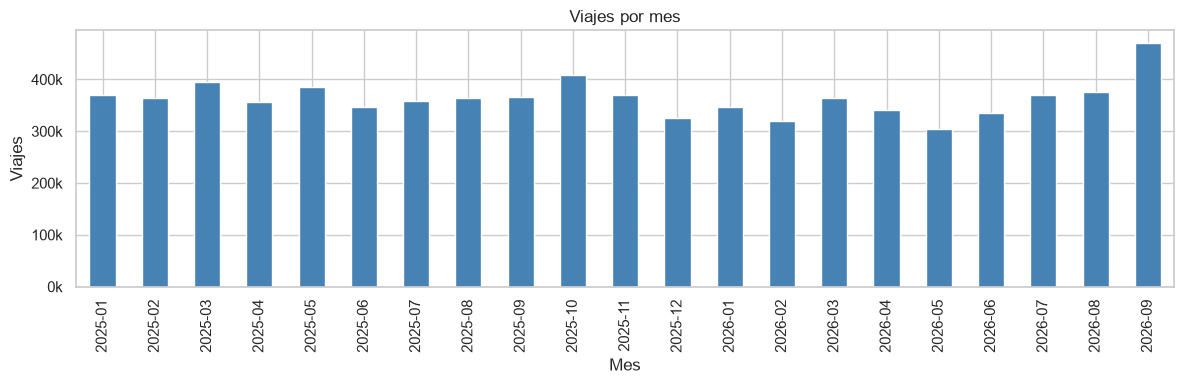

In [10]:
viajes_mes = df.groupby("mes").size()
fig, ax = plt.subplots(figsize=(12, 4))
viajes_mes.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Viajes por mes")
ax.set_xlabel("Mes"); ax.set_ylabel("Viajes")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1e3:,.0f}k")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "1.0_viajes_por_mes.png", dpi=150); plt.show()

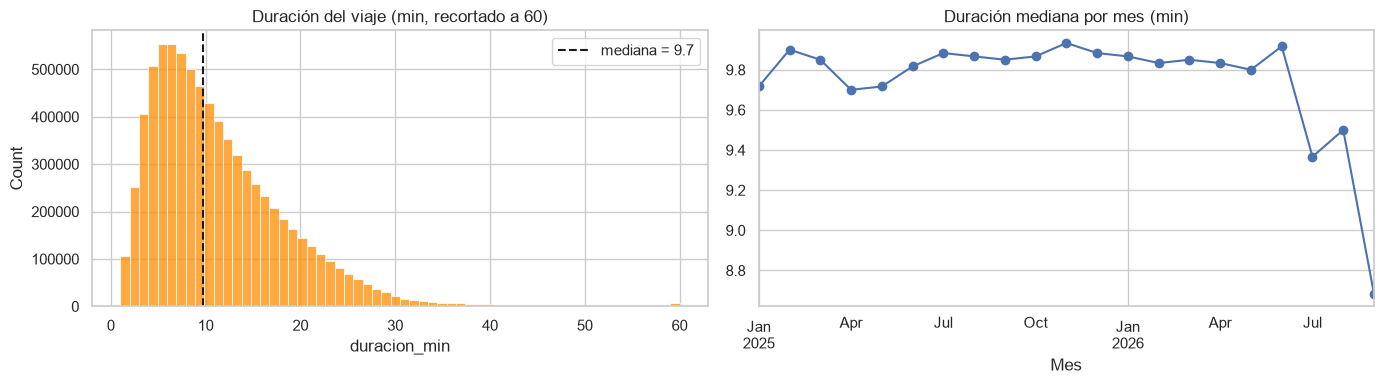

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["duracion_min"].clip(upper=60), bins=60, ax=axes[0], color="darkorange")
axes[0].set_title("Duración del viaje (min, recortado a 60)")
axes[0].axvline(df["duracion_min"].median(), color="k", ls="--", label=f"mediana = {df['duracion_min'].median():.1f}")
axes[0].legend()

por_mes = df.groupby("mes")["duracion_min"].median()
por_mes.plot(marker="o", ax=axes[1])
axes[1].set_title("Duración mediana por mes (min)"); axes[1].set_xlabel("Mes")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "1.0_duracion_viajes.png", dpi=150); plt.show()

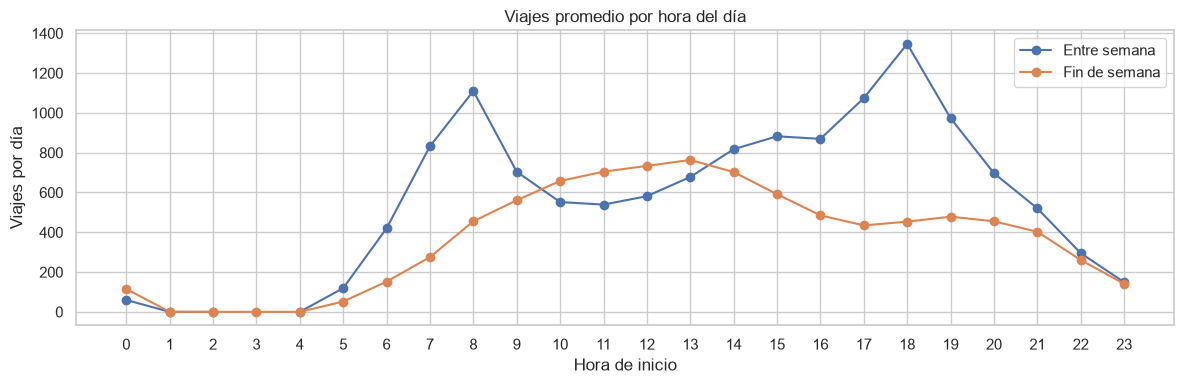

In [12]:
# Perfil horario: entre semana vs fin de semana (viajes promedio por día)
n_dias = df.groupby("fin_de_semana")["inicio"].apply(lambda s: s.dt.normalize().nunique())
perfil = df.groupby(["fin_de_semana", "hora"]).size().unstack(0)
perfil = perfil / n_dias.values
perfil.columns = ["Entre semana", "Fin de semana"]

fig, ax = plt.subplots(figsize=(12, 4))
perfil.plot(ax=ax, marker="o")
ax.set_title("Viajes promedio por hora del día"); ax.set_xlabel("Hora de inicio"); ax.set_ylabel("Viajes por día")
ax.set_xticks(range(24))
plt.tight_layout(); plt.savefig(FIGURES_DIR / "1.0_perfil_horario.png", dpi=150); plt.show()

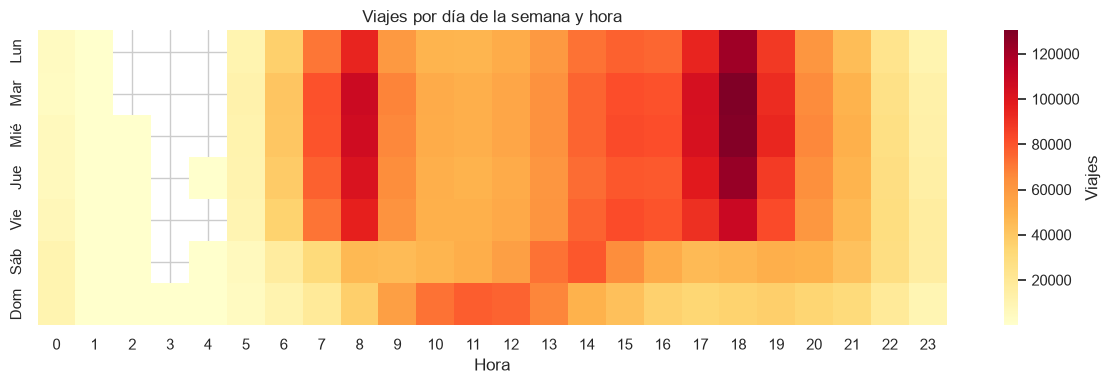

In [13]:
heat = df.groupby(["dia_semana", "hora"]).size().unstack()
heat.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(heat, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Viajes"})
ax.set_title("Viajes por día de la semana y hora"); ax.set_xlabel("Hora"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "1.0_heatmap_dia_hora.png", dpi=150); plt.show()

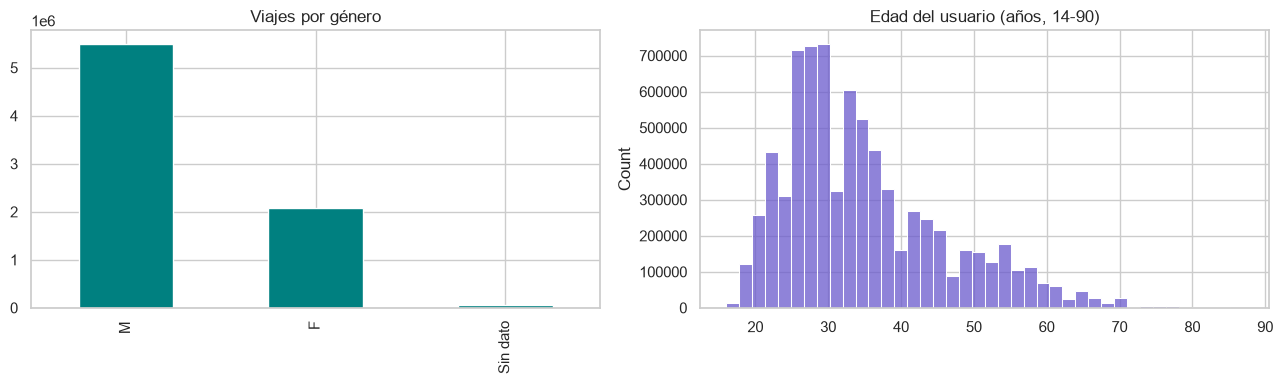

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["genero"].fillna("Sin dato").value_counts().plot(kind="bar", ax=axes[0], color="teal")
axes[0].set_title("Viajes por género"); axes[0].set_xlabel("")

edad = (df["inicio"].dt.year - df["anio_nacimiento"]).where(lambda s: s.between(14, 90))
sns.histplot(edad.dropna(), bins=40, ax=axes[1], color="slateblue")
axes[1].set_title("Edad del usuario (años, 14-90)")
plt.tight_layout(); plt.show()

## 5. Análisis por estación

Aquí se construye la tabla base que alimentará el clustering: una fila por estación con su volumen de salidas y llegadas,
capacidad y ubicación.

In [15]:
salidas = df.groupby("origen_id").size().rename("salidas")
llegadas = df.groupby("destino_id").size().rename("llegadas")

est = (
    stations.set_index("estacion_id")
    .join(salidas).join(llegadas)
    .fillna({"salidas": 0, "llegadas": 0})
)
est["total"] = est["salidas"] + est["llegadas"]
est["balance_neto"] = est["llegadas"] - est["salidas"]          # >0: acumula bicis, <0: se vacía
est["balance_rel"] = est["balance_neto"] / est["total"].replace(0, np.nan)
est["rotacion_por_anclaje"] = est["salidas"] / est["dpcapacity"]
est.sort_values("total", ascending=False).head(10)

,name,latitude,longitude,dpcapacity,salidas,llegadas,total,balance_neto,balance_rel,rotacion_por_anclaje
estacion_id,,,,,,,,,,
51,(GDL-049) Lopez Cotilla / PenitenciarÃ­a,20.67,-103.36,39,"155,718.00","192,186.00","347,904.00","36,468.00",0.10,"3,992.77"
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,20.68,-103.35,15,"126,848.00","150,388.00","277,236.00","23,540.00",0.08,"8,456.53"
271,(GDL-198) Av. Alcalde / C. Hospital,20.69,-103.35,31,"116,888.00","105,085.00","221,973.00","-11,803.00",-0.05,"3,770.58"
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,20.68,-103.35,23,"111,478.00","103,119.00","214,597.00","-8,359.00",-0.04,"4,846.87"
52,(GDL-050) C.Pedro Moreno /Federalismo,20.68,-103.35,23,"96,544.00","92,359.00","188,903.00","-4,185.00",-0.02,"4,197.57"
50,(GDL-048) C. Constancio HernÃ¡ndez/ Av. JuarÃ©z,20.67,-103.36,23,"92,301.00","95,056.00","187,357.00","2,755.00",0.01,"4,013.09"
54,(GDL-052) Av. Juarez /16 de Septiembre,20.68,-103.35,23,"85,091.00","89,091.00","174,182.00","4,000.00",0.02,"3,699.61"
260,(GDL-187) Av. 16 de Septiembre / C. Priscilia,20.67,-103.35,15,"65,401.00","82,052.00","147,453.00","16,651.00",0.11,"4,360.07"
38,(GDL-036) C. Marcos Castellanos/ C. Morelos,20.68,-103.36,23,"66,727.00","68,054.00","134,781.00","1,327.00",0.01,"2,901.17"


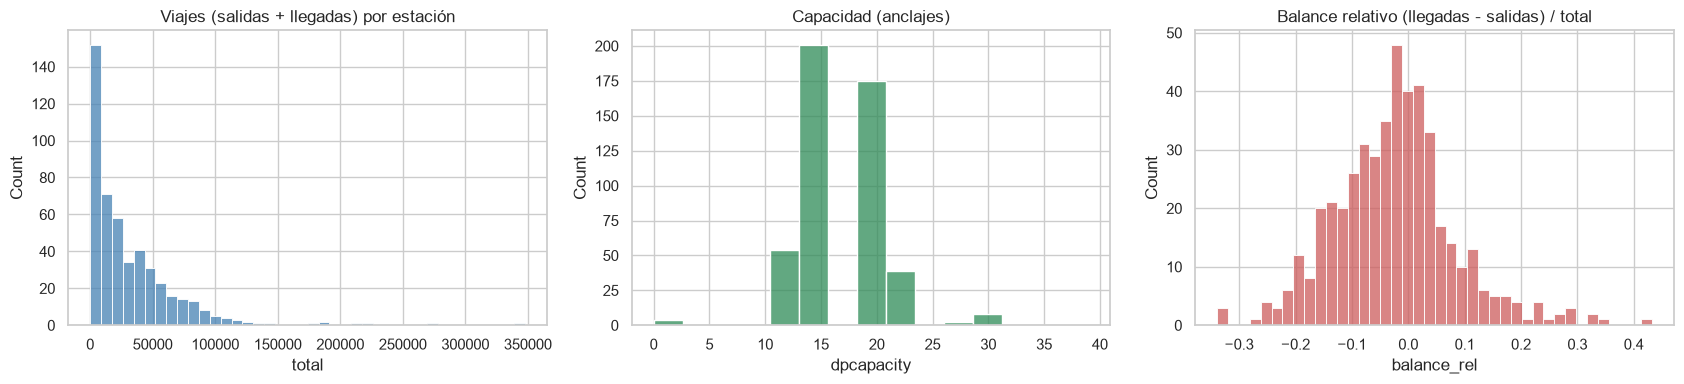

Estaciones con menos de 1,000 viajes en todo el periodo: 48


count       484.00
mean     31,587.02
std      37,986.82
min           0.00
25%       5,990.75
50%      19,734.50
75%      44,812.25
max     347,904.00
Name: total, dtype: float64

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(est["total"], bins=40, ax=axes[0], color="steelblue"); axes[0].set_title("Viajes (salidas + llegadas) por estación")
sns.histplot(est["dpcapacity"], bins=15, ax=axes[1], color="seagreen"); axes[1].set_title("Capacidad (anclajes)")
sns.histplot(est["balance_rel"].dropna(), bins=40, ax=axes[2], color="indianred"); axes[2].set_title("Balance relativo (llegadas - salidas) / total")
plt.tight_layout(); plt.show()

print("Estaciones con menos de 1,000 viajes en todo el periodo:", (est["total"] < 1000).sum())
est["total"].describe()

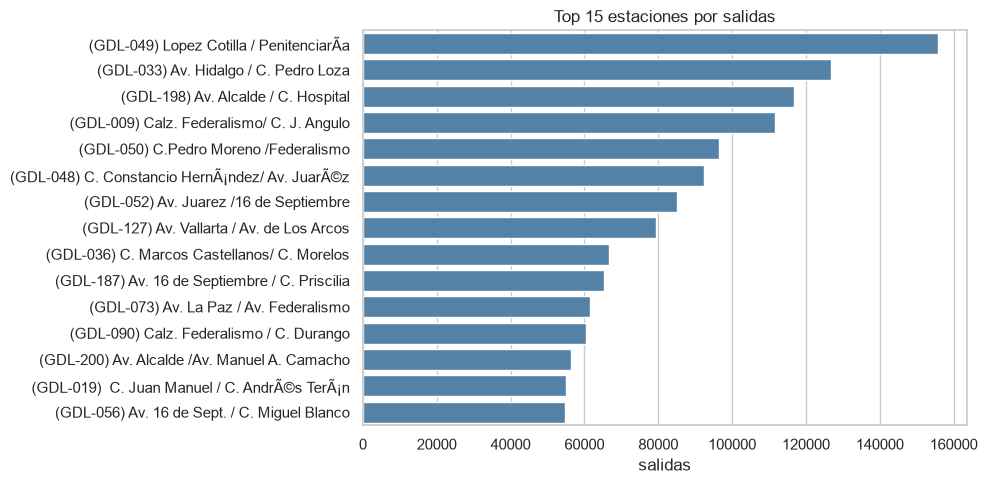

In [17]:
top = est.nlargest(15, "salidas")
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top, y="name", x="salidas", color="steelblue", ax=ax)
ax.set_title("Top 15 estaciones por salidas"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### 5.1 Ubicación geográfica

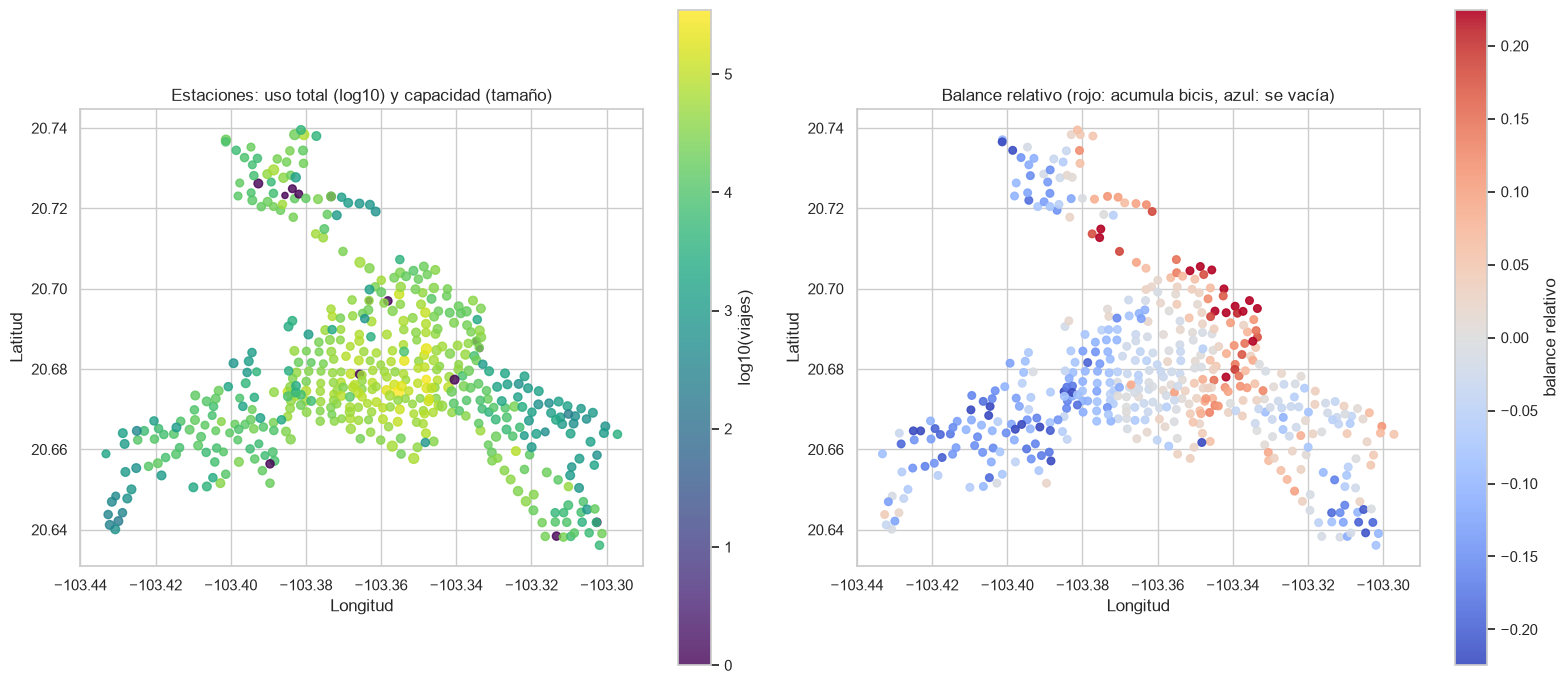

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sc = axes[0].scatter(est["longitude"], est["latitude"], c=np.log10(est["total"] + 1), cmap="viridis", s=20 + est["dpcapacity"], alpha=.8)
axes[0].set_title("Estaciones: uso total (log10) y capacidad (tamaño)")
plt.colorbar(sc, ax=axes[0], label="log10(viajes)")

lim = est["balance_rel"].abs().quantile(.95)
sc2 = axes[1].scatter(est["longitude"], est["latitude"], c=est["balance_rel"], cmap="coolwarm", vmin=-lim, vmax=lim, s=30, alpha=.9)
axes[1].set_title("Balance relativo (rojo: acumula bicis, azul: se vacía)")
plt.colorbar(sc2, ax=axes[1], label="balance relativo")
for a in axes:
    a.set_xlabel("Longitud"); a.set_ylabel("Latitud"); a.set_aspect(1 / np.cos(np.deg2rad(20.67)))
plt.tight_layout(); plt.savefig(FIGURES_DIR / "1.0_mapa_estaciones.png", dpi=150); plt.show()

**Mapa de las estaciones de acuerdo a la pagina de MiBici:**

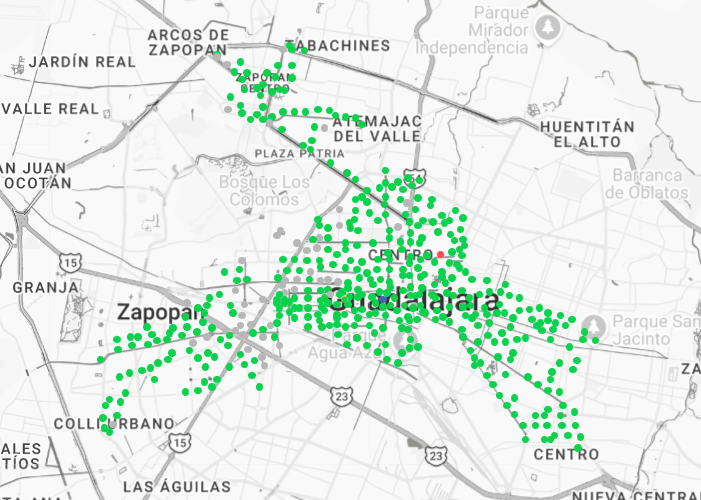

## 6. Perfiles temporales por estación (anticipo del clustering)

Se arma la matriz **estación × hora** (separando entre semana y fin de semana) con la *proporción* de salidas en cada hora.
Normalizar por estación hace que el clustering agrupe por **forma** del patrón y no por volumen.
Se consideran solo estaciones con volumen suficiente para tener un perfil estable.

Estaciones con >= 500 salidas: 437 de 484
(437, 48)


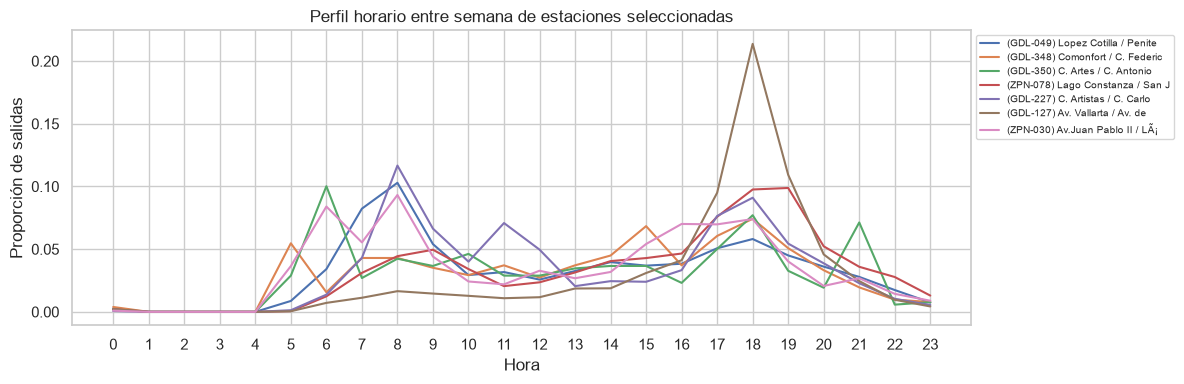

In [19]:
MIN_SALIDAS = 500
activas = est.index[est["salidas"] >= MIN_SALIDAS]
print(f"Estaciones con >= {MIN_SALIDAS} salidas: {len(activas)} de {len(est)}")

perfiles = (
    df[df["origen_id"].isin(activas)]
    .assign(tipo_dia=lambda d: np.where(d["fin_de_semana"], "fds", "lv"))
    .groupby(["origen_id", "tipo_dia", "hora"]).size()
    .unstack(["tipo_dia", "hora"], fill_value=0)
    .reindex(columns=pd.MultiIndex.from_product([["lv", "fds"], range(24)]), fill_value=0)
)
perfiles = perfiles.div(perfiles.sum(axis=1), axis=0)
perfiles.columns = [f"{t}_{h:02d}" for t, h in perfiles.columns]
print(perfiles.shape)

# Perfil de lunes a viernes de algunas estaciones representativas
muestra = est.loc[activas].nlargest(1, "salidas").index.tolist() + est.loc[activas].nsmallest(2, "salidas").index.tolist() \
    + est.loc[activas].nlargest(2, "balance_rel").index.tolist() + est.loc[activas].nsmallest(2, "balance_rel").index.tolist()
fig, ax = plt.subplots(figsize=(12, 4))
for i in dict.fromkeys(muestra):
    ax.plot(range(24), perfiles.loc[i, [f"lv_{h:02d}" for h in range(24)]].values, label=est.loc[i, "name"][:32])
ax.set_xticks(range(24)); ax.set_xlabel("Hora"); ax.set_ylabel("Proporción de salidas")
ax.set_title("Perfil horario entre semana de estaciones seleccionadas")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

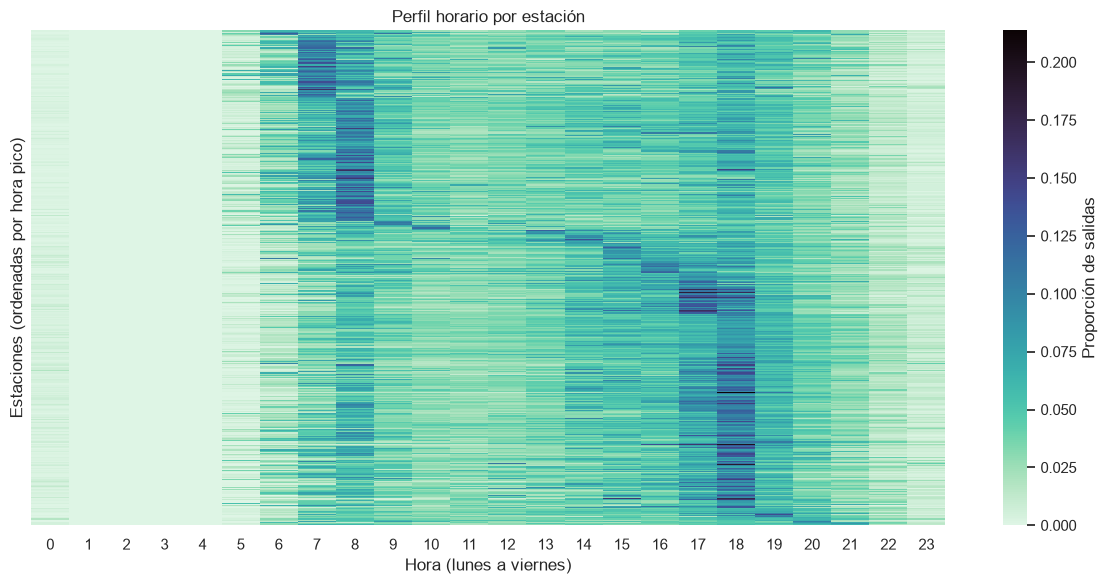

Hora pico entre semana (conteo de estaciones):
6       4
7      56
8     108
9       4
10      4
13      4
14      8
15     14
16     12
17     36
18    172
19      8
20      5
21      2


In [20]:
# ¿Se ven ya grupos? Mapa de calor de perfiles ordenados por hora del pico de salidas (entre semana)
cols_lv = [f"lv_{h:02d}" for h in range(24)]
orden = perfiles[cols_lv].values.argmax(axis=1).argsort(kind="stable")
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(perfiles[cols_lv].iloc[orden], cmap="mako_r", ax=ax, yticklabels=False, xticklabels=[h for h in range(24)],
            cbar_kws={"label": "Proporción de salidas"})
ax.set_xlabel("Hora (lunes a viernes)"); ax.set_ylabel("Estaciones (ordenadas por hora pico)")
ax.set_title("Perfil horario por estación")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "1.0_perfiles_estaciones.png", dpi=150); plt.show()

print("Hora pico entre semana (conteo de estaciones):")
print(pd.Series(perfiles[cols_lv].values.argmax(axis=1)).value_counts().sort_index().to_string())

## 7. Hallazgos y siguientes pasos

Completar/ajustar con los resultados observados arriba:

1. **Calidad:** revisar los porcentajes de nulos (`genero`, `anio_nacimiento`), duplicados y viajes con duración atípica; la limpieza propuesta descarta
   viajes < 1 min o > 180 min.
2. **Estaciones:** el uso por estación es muy desigual (cola larga); conviene filtrar estaciones con pocos viajes y/o normalizar.
3. **Patrones:** los perfiles horarios muestran picos distintos (p. ej. mañana/tarde entre semana vs. fin de semana), lo que sugiere que
   hay estructura para un clustering.

**Features candidatas para el clustering (un vector por estación):**

- Proporción de salidas y de llegadas por hora (entre semana / fin de semana).
- Balance neto relativo (llegadas - salidas) / total.
- Volumen total (log), capacidad y rotación por anclaje.
- Duración mediana de los viajes que salen de la estación.
- Ubicación (lat/lon) **solo para interpretar** los clusters en el mapa, no como feature, para que los grupos reflejen patrones de uso y no cercanía.

